# Réseau Analogique — Classification Disque centré en 0

**Seules les sections 0, 4 et 8 changent** par rapport au notebook XOR.

Exécuter dans l'ordre : **Kernel → Restart & Run All**

## 0. Imports & Configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import time

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"]  = 11
np.set_printoptions(precision=4, suppress=True)

# ── Fichiers CSV ──────────────────────────────────────────────
INPUT_CSV   = "input_min_conso.csv"
NEURON_CSV  = "neuron.csv"
SYN_EXC_CSV = "excitation20.csv"
SYN_INH_CSV = "inhibition20.csv"

FREQ_MERGE_TOL_HZ = 1000.0

# ── Architecture  [2, N_hidden, 2] ───────────────────────────
HIDDEN_SIZES = [8,8]   # ex: [4] -> 2-4-2  |  [4,4] -> 2-4-4-2

# ── Recherche ────────────────────────────────────────────────
N_RESTARTS        = 10
MAX_PASSES        = 8
SEED              = 42

# ── Dataset DISQUE ────────────────────────────────────────────
N_TRAIN      = 400
N_TEST       = 200
DISK_RADIUS  = 0.55   # rayon de séparation dans [-1, 1]²
MARGIN_DISK  = 0.08   # demi-largeur de l'anneau exclu autour du bord

# ── Score ─────────────────────────────────────────────────────
MARGIN_SCALE      = 5e-6
IMBALANCE_PENALTY = 0.15

print("Configuration OK.")

Configuration OK.


## 1. Fonctions utilitaires

In [2]:
def progress_bar(current, total, prefix="", suffix="", bar_len=35):
    filled = int(bar_len * current / total)
    bar    = "\u2588" * filled + "\u2591" * (bar_len - filled)
    pct    = int(100 * current / total)
    sys.stdout.write("\r  " + prefix + "[" + bar + "] "
                     + str(current) + "/" + str(total)
                     + " (" + str(pct) + "%)  " + suffix)
    sys.stdout.flush()
    if current == total:
        sys.stdout.write("\n")
        sys.stdout.flush()

def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if "Parameter" not in df.columns:
        raise ValueError(csv_path + ": colonne 'Parameter' introuvable")
    data_cols = [c for c in df.columns if c not in ["Parameter", "Unnamed: 1"]]
    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df["Parameter"] == row_name, data_cols]
        if row.empty:
            raise ValueError("Ligne '" + row_name + "' introuvable dans " + csv_path)
        values = pd.to_numeric(row.iloc[0], errors="coerce").to_numpy(dtype=float)
        if not allow_non_numeric and np.isnan(values).any():
            raise ValueError("Ligne '" + row_name + "' contient des NaN")
        return values
    return get_row

def get_clean_rows(reader, row_names):
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    mask = np.all(np.isfinite(np.vstack(rows)), axis=0)
    return [r[mask] for r in rows], mask

def interp_clip(x, xp, fp):
    return np.interp(np.asarray(x, float), xp, fp, left=fp[0], right=fp[-1])

def interp2d_bilinear(x, y, x_axis, y_axis, z_grid):
    x  = float(np.clip(x, x_axis[0], x_axis[-1]))
    y  = float(np.clip(y, y_axis[0], y_axis[-1]))
    ix = int(np.clip(np.searchsorted(x_axis, x) - 1, 0, len(x_axis) - 2))
    iy = int(np.clip(np.searchsorted(y_axis, y) - 1, 0, len(y_axis) - 2))
    x1, x2 = x_axis[ix], x_axis[ix + 1]
    y1, y2 = y_axis[iy], y_axis[iy + 1]
    tx = 0.0 if x2 == x1 else (x - x1) / (x2 - x1)
    ty = 0.0 if y2 == y1 else (y - y1) / (y2 - y1)
    return (z_grid[ix,   iy  ] * (1 - tx) * (1 - ty) +
            z_grid[ix+1, iy  ] * tx       * (1 - ty) +
            z_grid[ix,   iy+1] * (1 - tx) * ty       +
            z_grid[ix+1, iy+1] * tx       * ty)

def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    xm, ym = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(xm)
    return xm[o], ym[o]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol:
            groups[-1].append(v)
        else:
            groups.append([v])
    return np.array([np.mean(g) for g in groups])

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))]
                     for v in np.asarray(values, float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all, F_all, Y_all = (np.asarray(a, float) for a in (W_all, F_all, Y_all))
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            if not mask.any():
                raise ValueError("Point manquant W=" + str(w) + " F=" + str(f))
            z_grid[i, j] = np.mean(Y_all[mask])
    return W_unique, F_axis, z_grid

print("Fonctions utilitaires OK.")

Fonctions utilitaires OK.


## 2. Chargement des modèles Cadence

In [3]:
# ── Bloc d'entrée ─────────────────────────────────────────────
inp = read_cadence_rows(INPUT_CSV)
VEX_IN, FSPIKES_IN = inp("Vex"), inp("Fspikes")
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(VEX_IN, FSPIKES_IN)

def input_f_of_v(Vin_V):
    return interp_clip(Vin_V, INPUT_V_AXIS, INPUT_F_AXIS)

# ── Neurone ───────────────────────────────────────────────────
neuro = read_cadence_rows(NEURON_CSV)
IEX_NEURO, FSPIKES_NEURO = neuro("Iex"), neuro("Fspikes")
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(IEX_NEURO, FSPIKES_NEURO)

def neuron_f_of_i(Iin_A):
    return float(interp_clip(float(Iin_A), NEURON_I_AXIS, NEURON_F_AXIS))

# ── Synapse excitatrice ───────────────────────────────────────
syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ["W2", "Fpre", "Ipost"])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(
    W2_EXC, FPRE_EXC, IPOST_EXC, FREQ_MERGE_TOL_HZ)

def isyn_exc(Fpre_Hz, Wexc_um):
    return interp2d_bilinear(Wexc_um, Fpre_Hz, W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID)

# ── Synapse inhibitrice ───────────────────────────────────────
syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ["W2", "Fpre", "Ipost"])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(
    W2_INH, FPRE_INH, IPOST_INH, FREQ_MERGE_TOL_HZ)

def isyn_inh(Fpre_Hz, Winh_um):
    return interp2d_bilinear(Winh_um, Fpre_Hz, W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID)

# ── Constantes globales ───────────────────────────────────────
V_MIN       = float(INPUT_V_AXIS[0])
V_MAX       = float(INPUT_V_AXIS[-1])
LAYER_SIZES = [2] + HIDDEN_SIZES + [2]

print("Input  V : " + str(round(V_MIN*1e3,1)) + " mV -> " + str(round(V_MAX*1e3,1)) + " mV")
print("Neuron I : " + str(round(NEURON_I_AXIS[0]*1e12,1))
      + " pA -> " + str(round(NEURON_I_AXIS[-1]*1e12,1)) + " pA")
print("Exc W (um) : " + str(W_EXC_AXIS))
print("Inh W (um) : " + str(W_INH_AXIS))
print("Architecture : " + str(LAYER_SIZES))

Input  V : -100.0 mV -> 100.0 mV
Neuron I : 3.0 pA -> 1000.0 pA
Exc W (um) : [0.135  0.2858 0.4366 0.5874 0.7382 0.8889 1.04   1.191  1.341  1.492
 1.643  1.794  1.944  2.095  2.246  2.397  2.548  2.698  2.849  3.    ]
Inh W (um) : [0.135  0.1805 0.2261 0.2716 0.3171 0.3626 0.4082 0.4537 0.4992 0.5447
 0.5903 0.6358 0.6813 0.7268 0.7724 0.8179 0.8634 0.9089 0.9545 1.    ]
Architecture : [2, 8, 8, 2]


## 3. Propagation — identique au notebook de simulation

In [4]:
def layer_forward(Fin_vec_Hz, sign_matrix, width_matrix_um):
    """
    Propagation scalaire — une synapse à la fois.
    Identique au notebook de simulation Cadence.
    """
    N = len(Fin_vec_Hz)
    M = sign_matrix.shape[1]
    Iconn_mat_A = np.zeros((N, M))
    for i in range(N):
        for j in range(M):
            s = sign_matrix[i, j]
            w = width_matrix_um[i, j]
            if s == 1:
                Iconn_mat_A[i, j] = float(isyn_exc(Fin_vec_Hz[i], w))
            elif s == -1:
                Iconn_mat_A[i, j] = -float(isyn_inh(Fin_vec_Hz[i], w))
    Itot_vec_A  = np.sum(Iconn_mat_A, axis=0)
    Fout_vec_Hz = np.array([neuron_f_of_i(itot) for itot in Itot_vec_A])
    return Fout_vec_Hz, Iconn_mat_A, Itot_vec_A


def network_forward(Vin_vec_V, signs, widths):
    F = np.array([float(input_f_of_v(v)) for v in Vin_vec_V])
    history = [F.copy()]
    for sm, wm in zip(signs, widths):
        F, _, _ = layer_forward(F, sm, wm)
        history.append(F.copy())
    return F, history


def network_forward_dataset(V_dataset, signs, widths):
    return np.array([network_forward(Vin, signs, widths)[0] for Vin in V_dataset])


print("layer_forward OK.")

layer_forward OK.


## 4. Dataset DISQUE ← modifié

- **Classe 1** : $x^2 + y^2 < R^2$ (intérieur du disque)
- **Classe 0** : $x^2 + y^2 > R^2$ (extérieur)
- Les points dans l'anneau $|r - R| < $ `MARGIN_DISK` sont exclus pour éviter les cas ambigus près de la frontière.

Train : 400 pts  cl1(dedans)=108  cl0(dehors)=292
Test  : 200 pts  cl1(dedans)=53  cl0(dehors)=147


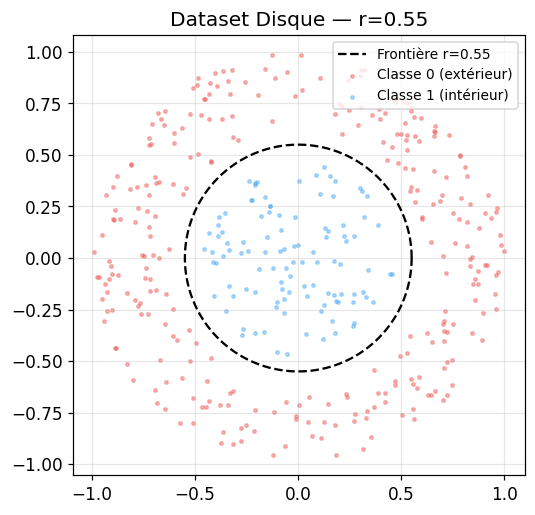

In [5]:
def label_disk(X):
    """1 si le point est à l'intérieur du disque de rayon DISK_RADIUS."""
    r2 = X[:, 0]**2 + X[:, 1]**2
    return (r2 < DISK_RADIUS**2).astype(int)


def make_dataset_disk(n, seed=0):
    rng = np.random.default_rng(seed)
    pts = []
    while sum(len(p) for p in pts) < n:
        batch = rng.uniform(-1.0, 1.0, size=(n * 4, 2))
        r = np.sqrt(batch[:, 0]**2 + batch[:, 1]**2)
        # Exclure les coins (r > 1) et l'anneau de marge autour du bord
        mask = (r <= 1.0) & (np.abs(r - DISK_RADIUS) > MARGIN_DISK)
        pts.append(batch[mask])
    data = np.vstack(pts)[:n]
    return data, label_disk(data)


def xy_to_voltage(X):
    return V_MIN + (np.asarray(X, float) + 1.0) * (V_MAX - V_MIN) / 2.0


X_train, y_train = make_dataset_disk(N_TRAIN, seed=SEED)
X_test,  y_test  = make_dataset_disk(N_TEST,  seed=SEED + 1)
V_train = xy_to_voltage(X_train)
V_test  = xy_to_voltage(X_test)

print("Train : " + str(len(y_train)) + " pts  cl1(dedans)=" + str(y_train.sum())
      + "  cl0(dehors)=" + str((1 - y_train).sum()))
print("Test  : " + str(len(y_test)) + " pts  cl1(dedans)=" + str(y_test.sum())
      + "  cl0(dehors)=" + str((1 - y_test).sum()))

fig, ax = plt.subplots(figsize=(5, 5))
theta = np.linspace(0, 2 * np.pi, 300)
ax.plot(DISK_RADIUS * np.cos(theta), DISK_RADIUS * np.sin(theta),
        "k--", lw=1.5, label="Frontière r=" + str(DISK_RADIUS))
ax.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1],
           s=5, alpha=0.4, c="#EF5350", label="Classe 0 (extérieur)")
ax.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1],
           s=5, alpha=0.4, c="#42A5F5", label="Classe 1 (intérieur)")
ax.set_title("Dataset Disque — r=" + str(DISK_RADIUS))
ax.set_aspect("equal")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Évaluation & Recherche par coordonnées

In [6]:
def evaluate_network(V_dataset, y_true, signs, widths):
    Fout  = network_forward_dataset(V_dataset, signs, widths)
    preds = np.argmax(Fout, axis=1)
    y     = np.asarray(y_true, int)
    mask0, mask1 = (y == 0), (y == 1)
    acc0 = float(np.mean(preds[mask0] == 0)) if mask0.any() else 0.0
    acc1 = float(np.mean(preds[mask1] == 1)) if mask1.any() else 0.0
    bal_acc    = 0.5 * (acc0 + acc1)
    margin0    = float(np.mean(Fout[mask0, 0] - Fout[mask0, 1])) if mask0.any() else 0.0
    margin1    = float(np.mean(Fout[mask1, 1] - Fout[mask1, 0])) if mask1.any() else 0.0
    bal_margin = 0.5 * (margin0 + margin1)
    score = bal_acc + MARGIN_SCALE * bal_margin - IMBALANCE_PENALTY * abs(acc0 - acc1)
    return {"preds": preds, "Fout": Fout, "acc0": acc0, "acc1": acc1,
            "bal_acc": bal_acc, "bal_margin": bal_margin, "score": score}


def print_results(label, m):
    print("\n=== " + label + " ===")
    print("  acc cl0  = " + str(round(m["acc0"], 4)))
    print("  acc cl1  = " + str(round(m["acc1"], 4)))
    print("  bal_acc  = " + str(round(m["bal_acc"], 4)))
    print("  marge    = " + str(round(m["bal_margin"] * 1e-3, 3)) + " kHz")
    print("  score    = " + str(round(m["score"], 6)))


ALL_CANDIDATES = [
    [(+1, float(w)) for w in W_EXC_AXIS] + [(-1, float(w)) for w in W_INH_AXIS]
    for _ in range(len(LAYER_SIZES) - 1)
]
print("Candidats par connexion : " + str(len(ALL_CANDIDATES[0]))
      + " (" + str(len(W_EXC_AXIS)) + " EXC + " + str(len(W_INH_AXIS)) + " INH)")


def random_network(rng):
    signs, widths = [], []
    for li, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:])):
        exc_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == +1]
        inh_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == -1]
        s = rng.choice([-1, 1], size=(n_in, n_out))
        w = np.zeros((n_in, n_out))
        for i in range(n_in):
            for j in range(n_out):
                w[i, j] = rng.choice(exc_w if s[i, j] == 1 else inh_w)
        signs.append(s)
        widths.append(w)
    return signs, widths


def coordinate_search():
    rng = np.random.default_rng(SEED)
    all_conns = [
        (l, i, j)
        for l, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:]))
        for i in range(n_in)
        for j in range(n_out)
    ]
    n_conns = len(all_conns)
    best_signs_g = best_widths_g = None
    best_val_score = best_train_score = -1e99
    best_history = []

    for restart in range(N_RESTARTS):
        sep = "=" * 60
        print("\n" + sep)
        print("RESTART " + str(restart + 1) + "/" + str(N_RESTARTS)
              + "  architecture " + str(LAYER_SIZES))
        print(sep)
        signs, widths = random_network(rng)
        tr = evaluate_network(V_train, y_train, signs, widths)
        va = evaluate_network(V_test,  y_test,  signs, widths)
        history = [{"pass": 0,
                    "tr_bal_acc": tr["bal_acc"], "tr_score": tr["score"],
                    "va_bal_acc": va["bal_acc"], "va_score": va["score"]}]
        print("  Init | tr_acc=" + str(round(tr["bal_acc"], 4))
              + " | va_acc=" + str(round(va["bal_acc"], 4)))
        t0 = time.time()

        for pass_idx in range(MAX_PASSES):
            improved = False
            conn_order = list(all_conns)
            rng.shuffle(conn_order)

            for conn_num, (l, i, j) in enumerate(conn_order):
                orig_s = signs[l][i, j]
                orig_w = widths[l][i, j]
                best_s, best_w, best_c = orig_s, orig_w, tr["score"]

                for cs, cw in ALL_CANDIDATES[l]:
                    if cs == orig_s and np.isclose(cw, orig_w):
                        continue
                    signs[l][i, j]  = cs
                    widths[l][i, j] = cw
                    ctr = evaluate_network(V_train, y_train, signs, widths)
                    if ctr["score"] > best_c:
                        best_c, best_s, best_w = ctr["score"], cs, cw
                    signs[l][i, j]  = orig_s
                    widths[l][i, j] = orig_w

                signs[l][i, j]  = best_s
                widths[l][i, j] = best_w
                if best_c > tr["score"]:
                    tr = evaluate_network(V_train, y_train, signs, widths)
                    improved = True

                elapsed = time.time() - t0
                suffix = ("pass " + str(pass_idx + 1) + "/" + str(MAX_PASSES)
                          + "  tr_acc=" + str(round(tr["bal_acc"], 3))
                          + "  " + str(int(elapsed)) + "s")
                progress_bar(conn_num + 1, n_conns, suffix=suffix)

            va = evaluate_network(V_test, y_test, signs, widths)
            history.append({"pass": pass_idx + 1,
                             "tr_bal_acc": tr["bal_acc"], "tr_score": tr["score"],
                             "va_bal_acc": va["bal_acc"], "va_score": va["score"]})
            print("  Pass " + str(pass_idx + 1)
                  + " | tr_acc=" + str(round(tr["bal_acc"], 4))
                  + " score=" + str(round(tr["score"], 5))
                  + " | va_acc=" + str(round(va["bal_acc"], 4))
                  + " score=" + str(round(va["score"], 5)))
            if not improved:
                print("  -> Converge")
                break

        if (va["score"] > best_val_score or
                (np.isclose(va["score"], best_val_score)
                 and tr["score"] > best_train_score)):
            best_signs_g     = [s.copy() for s in signs]
            best_widths_g    = [w.copy() for w in widths]
            best_val_score   = va["score"]
            best_train_score = tr["score"]
            best_history     = history
            print("  Nouveau meilleur val_score=" + str(round(best_val_score, 5)))

    return best_signs_g, best_widths_g, best_history


print("evaluate_network + coordinate_search OK.")

Candidats par connexion : 40 (20 EXC + 20 INH)
evaluate_network + coordinate_search OK.


## 6. Entraînement

In [7]:
n_conn = sum(LAYER_SIZES[i] * LAYER_SIZES[i+1] for i in range(len(LAYER_SIZES) - 1))
print("Architecture   : " + str(LAYER_SIZES))
print("Restarts       : " + str(N_RESTARTS))
print("Max passes     : " + str(MAX_PASSES))
print("Connexions     : " + str(n_conn))
print("Candidats/conn : " + str(len(ALL_CANDIDATES[0])))
print("Total évaluations max : " + str(N_RESTARTS * MAX_PASSES * n_conn * len(ALL_CANDIDATES[0])))

signs, widths, history = coordinate_search()

Architecture   : [2, 8, 8, 2]
Restarts       : 10
Max passes     : 8
Connexions     : 96
Candidats/conn : 40
Total évaluations max : 307200

RESTART 1/10  architecture [2, 8, 8, 2]


  Init | tr_acc=0.5 | va_acc=0.5
  [███████████████████████████████████] 96/96 (100%)  pass 1/8  tr_acc=0.5  1710s
  Pass 1 | tr_acc=0.5 score=0.35258 | va_acc=0.5 score=0.35197
  [███████████████████████████████████] 96/96 (100%)  pass 2/8  tr_acc=0.5  3394s
  Pass 2 | tr_acc=0.5 score=0.35609 | va_acc=0.5 score=0.35438
  [███████████████████████████████████] 96/96 (100%)  pass 3/8  tr_acc=0.5  5070s
  Pass 3 | tr_acc=0.5 score=0.35616 | va_acc=0.5 score=0.35447
  [███████████████████████████████████] 96/96 (100%)  pass 4/8  tr_acc=0.5  6735s
  Pass 4 | tr_acc=0.5 score=0.35617 | va_acc=0.5 score=0.35449
  [███████████████████████████████████] 96/96 (100%)  pass 5/8  tr_acc=0.5  8402s
  Pass 5 | tr_acc=0.5 score=0.35617 | va_acc=0.5 score=0.35449
  [███████████████████████████████████] 96/96 (100%)  pass 6/8  tr_acc=0.5  10070s
  Pass 6 | tr_acc=0.5 score=0.35617 | va_acc=0.5 score=0.35449
  -> Converge
  Nouveau meilleur val_score=0.35449

RESTART 2/10  architecture [2, 8, 8, 2]
  In

## 7. Résultats


=== TRAIN ===
  acc cl0  = 0.6404
  acc cl1  = 1.0
  bal_acc  = 0.8202
  marge    = 0.133 kHz
  score    = 0.766934

=== TEST ===
  acc cl0  = 0.5918
  acc cl1  = 1.0
  bal_acc  = 0.7959
  marge    = 0.13 kHz
  score    = 0.735345


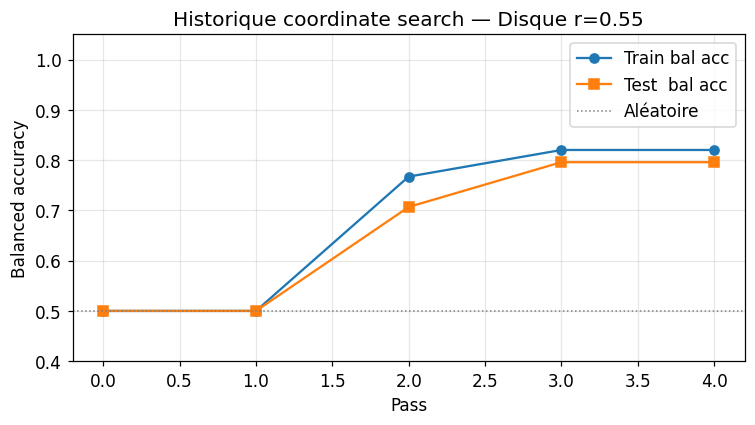

In [8]:
m_train = evaluate_network(V_train, y_train, signs, widths)
m_test  = evaluate_network(V_test,  y_test,  signs, widths)
print_results("TRAIN", m_train)
print_results("TEST",  m_test)

if history:
    passes = [h["pass"] for h in history]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(passes, [h["tr_bal_acc"] for h in history], "o-", label="Train bal acc")
    ax.plot(passes, [h["va_bal_acc"] for h in history], "s-", label="Test  bal acc")
    ax.axhline(0.5, color="gray", ls=":", lw=1, label="Aléatoire")
    ax.set_xlabel("Pass")
    ax.set_ylabel("Balanced accuracy")
    ax.set_title("Historique coordinate search — Disque r=" + str(DISK_RADIUS))
    ax.set_ylim(0.4, 1.05)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 8. Carte de décision ← frontière circulaire de référence ajoutée

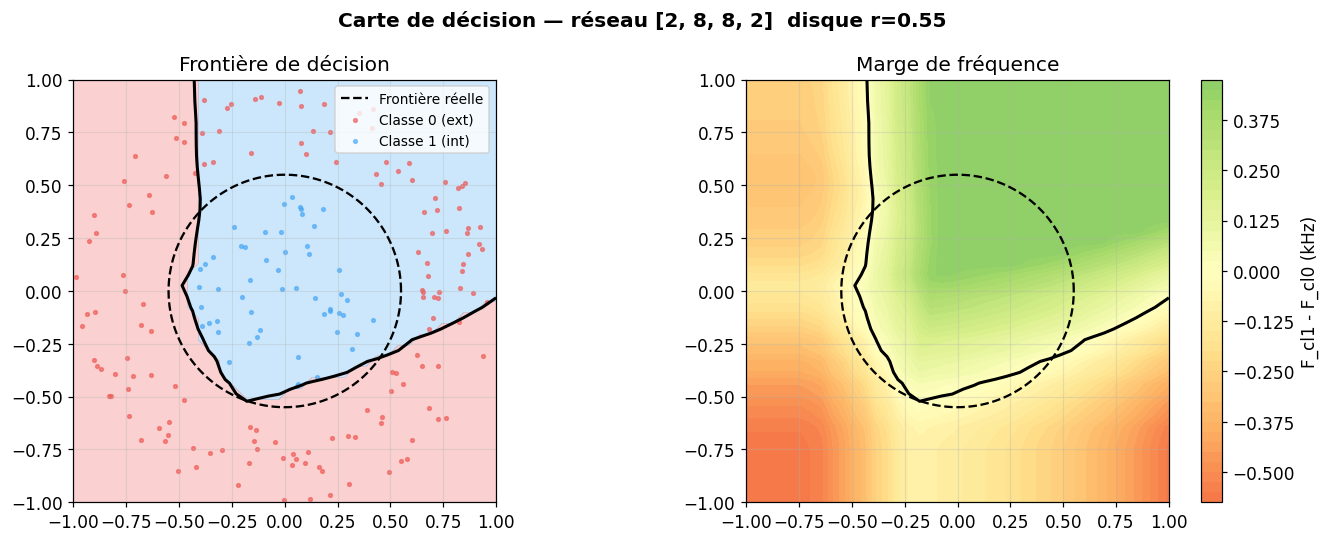

In [9]:
resolution = 40
xs = np.linspace(-1, 1, resolution)
ys = np.linspace(-1, 1, resolution)
XX, YY = np.meshgrid(xs, ys)
grid_V = xy_to_voltage(np.column_stack([XX.ravel(), YY.ravel()]))

Fout_grid   = network_forward_dataset(grid_V, signs, widths)
pred_grid   = np.argmax(Fout_grid, axis=1).reshape(XX.shape)
margin_grid = (Fout_grid[:, 1] - Fout_grid[:, 0]).reshape(XX.shape) * 1e-3

theta  = np.linspace(0, 2 * np.pi, 300)
circ_x = DISK_RADIUS * np.cos(theta)
circ_y = DISK_RADIUS * np.sin(theta)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Carte de décision — réseau " + str(LAYER_SIZES)
             + "  disque r=" + str(DISK_RADIUS), fontweight="bold")

ax = axes[0]
ax.contourf(XX, YY, pred_grid, levels=[-0.5, 0.5, 1.5],
            colors=["#EF535044", "#42A5F544"])
ax.contour(XX, YY, margin_grid, levels=[0], colors="k", linewidths=2)
ax.plot(circ_x, circ_y, "k--", lw=1.5, label="Frontière réelle")
ax.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1],
           s=6, c="#EF5350", alpha=0.6, label="Classe 0 (ext)")
ax.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1],
           s=6, c="#42A5F5", alpha=0.6, label="Classe 1 (int)")
ax.set_title("Frontière de décision")
ax.set_aspect("equal")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
vmax = max(abs(float(margin_grid.min())), abs(float(margin_grid.max())), 1.0)
cf = ax.contourf(XX, YY, margin_grid, levels=50, cmap="RdYlGn", vmin=-vmax, vmax=vmax)
plt.colorbar(cf, ax=ax, label="F_cl1 - F_cl0 (kHz)")
ax.contour(XX, YY, margin_grid, levels=[0], colors="k", linewidths=2)
ax.plot(circ_x, circ_y, "k--", lw=1.5)
ax.set_title("Marge de fréquence")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Diagnostic Cadence — plages de courant

In [10]:
## 9. Diagnostic Cadence — plages de courant
print("=" * 60)
print("  DIAGNOSTIC — Itot par couche vs plage neurone")
print("  Plage neurone : ["
      + str(round(NEURON_I_AXIS[0]*1e12, 1)) + " pA, "
      + str(round(NEURON_I_AXIS[-1]*1e12, 1)) + " pA]")
print("=" * 60)

all_itot = [[] for _ in range(len(LAYER_SIZES) - 1)]
for k, Vin in enumerate(V_train):
    if k % 50 == 0:
        print("  ... point " + str(k) + "/" + str(len(V_train)))
    F = np.array([float(input_f_of_v(v)) for v in Vin])
    for li, (sm, wm) in enumerate(zip(signs, widths)):
        F, _, Itot = layer_forward(F, sm, wm)
        all_itot[li].extend(Itot.tolist())

n_lo = NEURON_I_AXIS[0]
n_hi = NEURON_I_AXIS[-1]
for li, itots in enumerate(all_itot):
    itots = np.array(itots)
    lo, hi = itots.min(), itots.max()
    pct = 100 * np.mean((itots >= n_lo) & (itots <= n_hi))
    status = "OK" if pct == 100 else "ATTENTION " + str(round(100 - pct, 1)) + "% hors plage"
    print("  Couche " + str(li) + ": Itot in ["
          + str(round(lo*1e12, 1)) + ", " + str(round(hi*1e12, 1)) + "] pA  -> " + status)

print("=" * 60)
print("Courants hors plage = saturation sur Cadence.")

  DIAGNOSTIC — Itot par couche vs plage neurone
  Plage neurone : [3.0 pA, 1000.0 pA]
  ... point 0/400
  ... point 50/400
  ... point 100/400
  ... point 150/400
  ... point 200/400
  ... point 250/400
  ... point 300/400
  ... point 350/400
  Couche 0: Itot in [-23.1, 802.4] pA  -> ATTENTION 19.0% hors plage
  Couche 1: Itot in [691.6, 2351.2] pA  -> ATTENTION 62.5% hors plage
  Couche 2: Itot in [448.3, 453.8] pA  -> OK
Courants hors plage = saturation sur Cadence.


## 10. Export des poids pour Cadence

In [11]:
layer_names = (["In->H1"]
               + ["H" + str(k) + "->H" + str(k+1) for k in range(1, len(signs) - 1)]
               + ["H" + str(len(signs) - 1) + "->Out"])

print("\n=== POIDS FINAUX reseau " + str(LAYER_SIZES) + " ===")
for k, (s, w, ln) in enumerate(zip(signs, widths, layer_names)):
    print("\n  Couche " + str(k+1) + " [" + ln + "]  "
          + str(s.shape[0]) + "->" + str(s.shape[1]))
    print("    Signes :\n" + str(s))
    print("    Largeurs (um) :\n" + str(w))
    print("    EXC=" + str(int((s == +1).sum()))
          + "  INH=" + str(int((s == -1).sum())))

rows = []
for li, (s, w) in enumerate(zip(signs, widths)):
    n_in, n_out = s.shape
    for i in range(n_in):
        for j in range(n_out):
            rows.append({
                "layer":    li + 1,
                "pre":      i,
                "post":     j,
                "sign":     int(s[i, j]),
                "width_um": float(w[i, j]),
                "type":     "EXC" if s[i, j] == 1 else "INH"
            })

df_weights = pd.DataFrame(rows)
df_weights.to_csv("weights_cadence.csv", index=False)
print("\nweights_cadence.csv genere :")
print(df_weights.to_string(index=False))


=== POIDS FINAUX reseau [2, 8, 8, 2] ===

  Couche 1 [In->H1]  2->8
    Signes :
[[ 1  1  1 -1 -1  1 -1 -1]
 [ 1 -1 -1  1 -1  1  1 -1]]
    Largeurs (um) :
[[2.095  1.341  1.04   0.2716 0.2716 3.     0.135  0.8179]
 [3.     0.3626 0.3626 1.794  0.4537 0.8889 1.341  0.9089]]
    EXC=8  INH=8

  Couche 2 [H1->H2]  8->8
    Signes :
[[-1  1  1 -1  1  1  1  1]
 [-1  1 -1 -1 -1  1  1 -1]
 [-1 -1  1 -1  1 -1 -1  1]
 [-1 -1 -1  1 -1 -1 -1  1]
 [ 1  1 -1  1 -1  1  1  1]
 [ 1  1 -1  1  1  1  1 -1]
 [ 1 -1  1  1 -1  1  1  1]
 [-1 -1  1  1  1  1 -1  1]]
    Largeurs (um) :
[[0.135  2.849  2.095  0.6358 0.135  0.2858 0.135  1.04  ]
 [0.5447 0.5874 0.9089 0.135  1.     0.7382 1.492  0.5447]
 [0.135  0.6358 2.397  0.3626 1.04   0.9089 0.9089 3.    ]
 [0.4537 0.9089 0.6358 0.2858 0.4082 0.7268 0.2716 1.341 ]
 [2.397  0.4366 0.5447 0.5874 0.6813 0.7382 3.     0.2858]
 [0.135  2.397  0.9089 0.8889 0.5874 2.849  1.794  1.    ]
 [2.698  0.6358 1.191  0.4366 0.4082 1.191  2.548  1.643 ]
 [0.4537 0.3171 1